# NLP Assignment 2: Apply Word2Vec to Downstream Tasks

In this assignment, you will perform two tasks using Word2Vec:
- Unsupervised PoS tagging using K-Means
- Unsupervised Extractive Summarisation

**We will randomly run 15 submissions. If any bug occurs during execution OR the results fall outside a reasonable reproducible range compared to the logged results, the submission will receive 0 mark for this assignment.**

## 0. Load pre-trained Glove embeddings

In this step, we load the pre-trained GloVe word embeddings from the text file specified by glove_path.
The function load_glove reads the file line by line and processes each entry by:
- Splitting each line into the token (word) and its corresponding embedding values;
- Converting the embedding values from strings to float32 arrays;
- Cleaning the token by removing non-breaking spaces and skipping tokens that contain whitespace or are empty;
- Optionally limiting the number of loaded lines through the max_lines parameter.

The final result is stored in the dictionary glove_vectors. Please download the model (glove.2024.wikigiga.100d.zip, 560MB) at https://nlp.stanford.edu/projects/glove/.

In [1]:
import numpy as np
from typing import Optional

def load_glove(path: str, dim: int = 100, max_lines: Optional[int] = None) -> dict:
    vectors = {}
    nb_space = u"\xa0"
    with open(path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if max_lines is not None and i >= max_lines:
                break
            parts = line.strip().split()
            if len(parts) <= dim:
                continue
            tail = parts[-dim:]
            try:
                vec = np.array([float(x) for x in tail], dtype=np.float32)
            except ValueError:
                continue
            token = " ".join(parts[:-dim]).replace(nb_space, " ").strip()
            if " " in token or token == "":
                continue  
            vectors[token] = vec
    return vectors

glove_path = "/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/100d.txt"
glove_vectors = load_glove(glove_path)

print(f"GloVe Loaded. Vocab size: {len(glove_vectors):,}")

GloVe Loaded. Vocab size: 1,287,614


## 1. Apply Word2Vec to Unsupervised PoS Tagging.
In this step, we use word embeddings to perform unsupervised part-of-speech (PoS) tagging through clustering.
The key idea is that words with similar syntactic functions tend to appear in similar contexts and therefore have similar vector representations in the embedding space.

The process involves:
- Using pre-trained Word2Vec (or GloVe) embeddings to represent each word as a dense vector;
- Grouping words into clusters based on their embedding similarity using an unsupervised clustering algorithm (e.g. K-Means);
- Evaluating the quality of the induced clusters against gold PoS tags using information-theoretic metrics.
- Visualise the clustered embeddings.

In this task, we will use K-Means to group text from brown corpus.

### 1.1 Download the Brown Corpus.
We download the brown corpus from nltk to obtain the sentences and corresponding PoS tags. We use the first 500 instances for this task.

The number of unique PoS tags in this subset will be used as the number of clusters (k) in the later clustering step.

In [2]:
import nltk

nltk.download('brown')
nltk.download('universal_tagset')

from nltk.corpus import brown

tagged_sents = brown.tagged_sents(tagset='universal')[:500]
upos_tags = [t for sent in tagged_sents for (_, t) in sent]


# Calculate the number of PoS tags, which will be used as the k for clustering.
unique_upos = sorted(set(upos_tags))
print(f"PoS tag num: {len(unique_upos)}")
print("PoS list:", unique_upos)


PoS tag num: 12
PoS list: ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']


[nltk_data] Downloading package brown to /home/potato/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package universal_tagset to
[nltk_data]     /home/potato/nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!


In [3]:
tagged_sents[:5]

[[('The', 'DET'),
  ('Fulton', 'NOUN'),
  ('County', 'NOUN'),
  ('Grand', 'ADJ'),
  ('Jury', 'NOUN'),
  ('said', 'VERB'),
  ('Friday', 'NOUN'),
  ('an', 'DET'),
  ('investigation', 'NOUN'),
  ('of', 'ADP'),
  ("Atlanta's", 'NOUN'),
  ('recent', 'ADJ'),
  ('primary', 'NOUN'),
  ('election', 'NOUN'),
  ('produced', 'VERB'),
  ('``', '.'),
  ('no', 'DET'),
  ('evidence', 'NOUN'),
  ("''", '.'),
  ('that', 'ADP'),
  ('any', 'DET'),
  ('irregularities', 'NOUN'),
  ('took', 'VERB'),
  ('place', 'NOUN'),
  ('.', '.')],
 [('The', 'DET'),
  ('jury', 'NOUN'),
  ('further', 'ADV'),
  ('said', 'VERB'),
  ('in', 'ADP'),
  ('term-end', 'NOUN'),
  ('presentments', 'NOUN'),
  ('that', 'ADP'),
  ('the', 'DET'),
  ('City', 'NOUN'),
  ('Executive', 'ADJ'),
  ('Committee', 'NOUN'),
  (',', '.'),
  ('which', 'DET'),
  ('had', 'VERB'),
  ('over-all', 'ADJ'),
  ('charge', 'NOUN'),
  ('of', 'ADP'),
  ('the', 'DET'),
  ('election', 'NOUN'),
  (',', '.'),
  ('``', '.'),
  ('deserves', 'VERB'),
  ('the', 'DET'),

### 1.2 Build Token Embeddings and Gold Tags

In this step, we align the words in the Brown corpus with the pre-trained GloVe embeddings and extract the corresponding PoS tags.

The process involves:
- Collecting words from the tagged sentences and converting them to lowercase;
- Checking whether each word exists in the GloVe vocabulary;
-- If in-vocabulary, we store its embedding and gold PoS tag;
-- If out-of-vocabulary (OOV), we skip it;

The outputs include:
- token_embeddings: mapping from each unique in-vocabulary word to its embedding vector;
- vocab_words: list of unique in-vocabulary word types;
- input_tokens and gold_tags: word-level tokens and their corresponding PoS tags (for evaluation only);
- X contains the GloVe embeddings of unique word types with the shape (V, D), where V is the number of unique in-vocab word types and D is the embedding dimension.


In [4]:
import numpy as np
from typing import Dict, List, Tuple

def build_token_embeddings_and_gold_tags(
    tagged_sents: List[List[Tuple[str, str]]],
    glove_vectors: Dict[str, np.ndarray],
    lowercase: bool = True
):
    token_embeddings: Dict[str, np.ndarray] = {} # subset of glove vectotrs in the tagged sentences 
    input_tokens: List[str] = [] # list of words, and their corresponding tags according to the brown dataset
    gold_tags: List[str] = []

    total_tokens = 0
    iv_count = 0 # in vocab count
    oov_count = 0

    for sent in tagged_sents:
        for w, tag in sent:
            total_tokens += 1
            w_proc = w.lower() if lowercase else w

            if w_proc in glove_vectors:
                iv_count += 1
                input_tokens.append(w_proc)
                gold_tags.append(tag)

                if w_proc not in token_embeddings:
                    token_embeddings[w_proc] = glove_vectors[w_proc]
            else:
                oov_count += 1

    vocab_words = list(token_embeddings.keys())
    if len(vocab_words) == 0:
        raise ValueError("Please check your data.")
    d = token_embeddings[vocab_words[0]].shape[0]
    X = np.vstack([token_embeddings[w] for w in vocab_words]).astype(np.float32)
    assert X.shape == (len(vocab_words), d)

    stats = {
        "total_tokens": total_tokens,
        "in_vocab_tokens": iv_count,
        "oov_tokens": oov_count,
        "oov_ratio": oov_count / max(total_tokens, 1),
        "vocab_size_unique_in_glove": len(vocab_words),
        "embedding_dim": d,
    }
    return token_embeddings, vocab_words, X, input_tokens, gold_tags, stats


token_embeddings, vocab_words, X, input_tokens, gold_tags, stats = build_token_embeddings_and_gold_tags(
    tagged_sents=tagged_sents,
    glove_vectors=glove_vectors,
    lowercase=True
)


print("Finish building")
print(f"- Total token num: {stats['total_tokens']}")
print(f"- In-vocab token num: {stats['in_vocab_tokens']}")
print(f"- OOV token num: {stats['oov_tokens']} ({stats['oov_ratio']:.2%})")
print(f"- In-vocab type num: {stats['vocab_size_unique_in_glove']}")



Finish building
- Total token num: 11711
- In-vocab token num: 11558
- OOV token num: 153 (1.31%)
- In-vocab type num: 2626


### 1.3 Cluster Word Embeddings with K-Means (Unsupervised PoS Induction)

In this step, we run **K-Means** on the (unique) word-type embeddings to induce PoS-like clusters.  
The intuition is that words with similar syntactic or semantic behaviour are close in the embedding space and therefore tend to fall into the same cluster.

#### Process
- L2-normalise all word vectors (row-wise) to stabilise distance comparisons;
- Initialise centroids with **k-means++** for better starting positions;
- Run multiple random restarts (`n_init` times), each using Lloyd’s algorithm up to `max_iter`;
- Select the run with the **lowest inertia** (tightest clusters);
- Store a **type-level** mapping `word2cluster` for downstream evaluation.

#### Inputs
- `X ∈ ℝ^{V×D}`: embedding matrix of unique in-vocab word types (same order as `vocab_words`);
- `vocab_words` (length = V): list of unique word types;
- `k`: number of clusters (here set to the number of UPOS tags);
- `n_init`, `max_iter`, `tol`: clustering hyperparameters;
- `random_state`: seed for reproducible initialisations.

#### Outputs (stored in the trained model)
- `labels_ ∈ {0,…,k−1}^V`: cluster ID for each word type;
- `centroids_ ∈ ℝ^{k×D}`: learned cluster centroids;
- `inertia_`: within-cluster sum of squared distances (lower is better);
- `n_iter_`: number of iterations used in the best run;
- `best_seed_`: random seed corresponding to the best run;
- `word2cluster: Dict[str, int]`: mapping from word type to cluster ID, later used to assign token-level labels.

Note: The `labels_` are cluster labels, not gold PoS tags. They are later used for evaluation against the gold labels (PoS tags) at the token level to compute evaluation metrics (e.g., Mutual Information, Normalised Mutual Information, V-measure, Variation of Information).


In [5]:
import numpy as np
from typing import List, Dict, Optional

class KMeansPOSTagger:
    """
    Minimal K-Means implementation for unsupervised PoS induction.
    - Uses L2 normalisation on input embeddings.
    - Uses k-means++ for centroid initialisation.
    - Runs multiple random restarts and keeps the best result.
    - Stores word2cluster mapping for evaluation.
    """

    def __init__(
        self,
        k: int,
        n_init: int = 10,
        max_iter: int = 100,
        tol: float = 1e-4,
        random_state: Optional[int] = None,
        init: str = "k-means++",
    ):
        """
        Parameters
        ----------
        k : int
            Number of clusters (here equal to the number of UPOS tags).
        n_init : int
            Number of random restarts. The best run (lowest inertia) is kept.
        max_iter : int
            Maximum number of iterations for Lloyd’s algorithm in each run.
        tol : float
            Convergence tolerance. If centroid shift or inertia improvement is smaller than this value, stop iterating.
        random_state : Optional[int]
            Seed for reproducibility. If None, uses random seed.
        init : str
            Initialisation method for centroids. 
            Supported: "k-means++" (default) or "random".
        """
        self.k = k
        self.n_init = n_init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.init = init

        # Learned attributes (after clustering)
        self.vocab_: List[str] = [] # list of unique in-vocab word types
        self.labels_: Optional[np.ndarray] = None # cluster label per word type
        self.centroids_: Optional[np.ndarray] = None # learned centroid matrix [k, d]
        self.inertia_: Optional[float] = None # final inertia
        self.n_iter_: Optional[int] = None # iterations in the best run
        self.best_seed_: Optional[int] = None # random seed of best run
        self.word2cluster_: Dict[str, int] = {} # mapping word -> cluster ID

    @staticmethod
    def _l2norm_rows(X: np.ndarray, eps: float = 1e-12) -> np.ndarray:
        """
        L2-normalise each row of the embedding matrix X to unit length.
        This ensures all vectors have the same scale for clustering.
        """
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        return X / (norms + eps)

    @staticmethod
    def _kmeans_pp_init(X: np.ndarray, k: int, rng) -> np.ndarray:
        """
        Initialise centroids using k-means++:
        - Choose the first centroid randomly.
        - Choose each subsequent centroid with probability proportional to its squared distance to the nearest centroid.
        """
        n, d = X.shape
        centroids = np.empty((k, d), dtype=X.dtype)
        first = int(rng.integers(0, n))
        centroids[0] = X[first]
        closest_sq = np.full(n, np.inf, dtype=X.dtype)
        for i in range(1, k):
            dists = np.linalg.norm(X - centroids[i-1], axis=1) ** 2
            closest_sq = np.minimum(closest_sq, dists)
            probs = closest_sq / (closest_sq.sum() + 1e-12)
            idx = int(rng.choice(n, p=(probs / probs.sum())))
            centroids[i] = X[idx]
        return centroids

    @staticmethod
    def _assign(X: np.ndarray, C: np.ndarray) -> np.ndarray:
        """
        Assign each point in X to the nearest centroid in C.
        Distance metric: squared Euclidean distance.
        Returns
        -------
        labels : np.ndarray
            Shape (n,), cluster index for each data point.
        """
        x2 = (X**2).sum(axis=1, keepdims=True)
        c2 = (C**2).sum(axis=1, keepdims=True).T
        d2 = x2 + c2 - 2 * (X @ C.T)
        return d2.argmin(axis=1)

    @staticmethod
    def _update(X: np.ndarray, y: np.ndarray, k: int) -> np.ndarray:
        """
        Recompute cluster centroids:
        - For each cluster, take the mean of all assigned points.
        """
        d = X.shape[1]
        C = np.zeros((k, d), dtype=X.dtype)
        for i in range(k):
            m = (y == i)
            C[i] = X[m].mean(axis=0) if m.any() else X[np.random.randint(0, len(X))]
        return C

    @staticmethod
    def _inertia(X: np.ndarray, y: np.ndarray, C: np.ndarray) -> float:
        """
        Compute total within-cluster sum of squared distances (inertia).
        Lower inertia = tighter clusters.
        """
        D = X - C[y]
        return float((D**2).sum())

    def fit(self, X: np.ndarray, vocab_words: List[str]):
        """
        Run K-Means clustering on the embedding matrix.

        Steps:
        1. Use L2 normalisation on X.
        2. Run multiple random restarts (n_init times).
        3. For each run:
           - Initialise centroids (k-means++ or random)
           - Run Lloyd's algorithm until convergence or max_iter
           - Track best run with minimal inertia
        4. Save best clustering result and build word2cluster mapping.

        Parameters
        ----------
        X : np.ndarray
            Word embedding matrix of shape [V, D], where V is vocab size and D is embedding dim.
        vocab_words : List[str]
            List of word types corresponding to the rows in X.
        """
        assert len(vocab_words) == X.shape[0], "vocab length must match X rows"
        self.vocab_ = list(vocab_words)

        # L2 normalisation
        X_in = self._l2norm_rows(X)

        # Multiple restarts
        rng_base = np.random.default_rng(self.random_state)
        best = None

        for _ in range(self.n_init):
            seed = int(rng_base.integers(0, 2**31 - 1))
            rng = np.random.default_rng(seed)

            # Initialisation
            if self.init == "k-means++":
                C = self._kmeans_pp_init(X_in, self.k, rng)
            else:
                C = X_in[rng.choice(len(X_in), size=self.k, replace=False)].copy()

            # Iterations
            prev_inertia = None
            for it in range(self.max_iter):
                y = self._assign(X_in, C)
                C_new = self._update(X_in, y, self.k)
                inertia = self._inertia(X_in, y, C_new)
                shift = np.linalg.norm(C_new - C)
                C = C_new
                if prev_inertia is not None and abs(prev_inertia - inertia) < self.tol:
                    break
                if shift < self.tol:
                    break
                prev_inertia = inertia

            # Save run
            res = {"labels": y, "centroids": C, "inertia": inertia, "n_iter": it + 1, "seed": seed}
            if best is None or res["inertia"] < best["inertia"]:
                best = res

        # Save best result
        self.labels_ = best["labels"]
        self.centroids_ = best["centroids"]
        self.inertia_ = best["inertia"]
        self.n_iter_ = best["n_iter"]
        self.best_seed_ = best["seed"]
        self.word2cluster_ = {w: int(c) for w, c in zip(self.vocab_, self.labels_)}

        # Print logs
        print(" K-Means finished")
        print(f"Inertia: {self.inertia_:.4f}")
        print(f"Iterations: {self.n_iter_}")
        print(f"Best init seed: {self.best_seed_}")

        return self


# Run K-Means clustering
k = len(unique_upos)  # number of clusters = number of UPOS tags
tagger = KMeansPOSTagger(k=k, n_init=50, max_iter=200, random_state=42)
tagger.fit(X, vocab_words)
word2cluster = tagger.word2cluster_

 K-Means finished
Inertia: 1468.8541
Iterations: 39
Best init seed: 184566854


### 1.4 Evaluation: Cluster Quality vs. Gold PoS Tags (20%)

In this step, we evaluate how well the induced clusters align with the gold PoS tags from the corpus.  
We build a contingency matrix between cluster assignments and gold labels and compute several widely used information-theoretic evaluation metrics.

1. Map tokens to cluster IDs:  
   - Each token is assigned to the cluster of its corresponding word type.

2. Build contingency matrix:  
   - Rows correspond to predicted clusters;  
   - Columns correspond to gold PoS tags;  
   - Each cell counts how many tokens from a given cluster belong to each gold tag.

3. Compute evaluation metrics:
   - Mutual Information (MI): Measures how much information cluster assignments and gold labels share.  
   - Normalised Mutual Information (NMI): Normalises MI by the entropy of both cluster and tag distributions.  
   - Homogeneity: Measures whether each cluster contains only members of a single gold class.  
   - Completeness: Measures whether all members of a gold class are assigned to the same cluster.  
   - V-measure: Harmonic mean of Homogeneity and Completeness.  
   - Variation of Information (VI): Distance between cluster and gold distributions (lower is better).

In [6]:
import numpy as np
from typing import List, Tuple

def build_contingency(
    cluster_ids: List[int],
    gold_tags: List[str],
) -> Tuple[np.ndarray, List[int], List[str]]:
    """
    Build contingency matrix C[cluster, tag].
    Labels are automatically sorted internally.
    """
    # Please complete your code here.
    C = np.zeros((len(set(cluster_ids)), len(set(gold_tags))))
    tmp = sorted(set(gold_tags))
    gold_tags_indexed = {tag: i for i, tag in enumerate(tmp)}
    transformed_gold_tags = [gold_tags_indexed[tag] for tag in gold_tags]
    for cluster_id, gold_tag in zip(cluster_ids, transformed_gold_tags): 
        C[cluster_id, gold_tag] += 1 
    clusters = sorted(set(cluster_ids))
    tags = sorted(set(gold_tags))
    return C, clusters, tags

def entropy(p: np.ndarray) -> float:
    """Compute Shannon entropy H(p)."""
    # Please complete your code here.
    p = p[p>0]
    t = p * np.log2(p) 
    H = - sum(t)

    return float(H)

def mutual_information(C: np.ndarray) -> float:
    """Compute mutual information I(C;T)."""
    # Please complete your code here.
    total = C.sum()
    p_cluster = C.sum(axis=1) / total
    p_tag = C.sum(axis=0) / total
    p_xy = C / total

    t = np.zeros(C.shape)
    for i in range(C.shape[0]): 
        for j in range(C.shape[1]): 
            if p_xy[i, j] <= 0: 
                continue
            t[i, j] = p_xy[i, j] * np.log2(p_xy[i, j] / (p_cluster[i] * p_tag[j]))
    I = t.sum()
    return float(I)

def normalised_mutual_information(C: np.ndarray) -> float:
    """Compute normalised mutual information (NMI) with sqrt normalisation."""
    # Please complete your code here.
    total = C.sum()
    p_cluster = C.sum(axis=1) / total
    p_tag = C.sum(axis=0) / total

    NMI = mutual_information(C) / (np.sqrt(entropy(p_cluster) * entropy(p_tag)))
    return float(NMI)

def homogeneity(C: np.ndarray) -> float:
    """Compute homogeneity."""
    # Please complete your code here.
    total = C.sum()
    p_cluster = C.sum(axis=1) / total
    p_tag = C.sum(axis=0) / total
    p_xy = C / total

    t = np.zeros(C.shape)
    for i in range(C.shape[0]): 
        for j in range(C.shape[1]): 
            if p_xy[i, j] <= 0: 
                continue
            t[i, j] = p_xy[i, j] * np.log2(p_xy[i, j] / (p_cluster[i]))
    h_tc = t.sum()

    H = 1 + (h_tc / entropy(p_tag)) 

    return float(H)

def completeness(C: np.ndarray) -> float:
    """Compute completeness."""
    # Please complete your code here.
    total = C.sum()
    p_cluster = C.sum(axis=1) / total
    p_tag = C.sum(axis=0) / total
    p_xy = C / total

    t = np.zeros(C.shape)
    for i in range(C.shape[0]): 
        for j in range(C.shape[1]): 
            if p_xy[i, j] <= 0: 
                continue
            t[i, j] = p_xy[i, j] * np.log2(p_xy[i, j] / (p_tag[j]))
    h_ct = t.sum()

    Comp = 1 + (h_ct / entropy(p_cluster)) 

    return float(Comp)

def v_measure(C: np.ndarray) -> float:
    """Compute V-measure."""
   # Please complete your code here.
    h = homogeneity(C)
    c = completeness(C)

    V = 2 * h * c / (h + c)

    return float(V)

def variation_of_information(C: np.ndarray) -> float:
    """Compute Variation of Information (VI)."""
    # Please complete your code here.
    total = C.sum()
    p_cluster = C.sum(axis=1) / total
    p_tag = C.sum(axis=0) / total

    VI = entropy(p_cluster) + entropy(p_tag) - 2 * mutual_information(C)
    return float(VI)

# Map each token in the corpus to its cluster ID from KMeans
cluster_ids_for_tokens = [word2cluster[w] for w in input_tokens]

# Evaluate the PoS tagging performance
C, clusters, tags = build_contingency(cluster_ids_for_tokens, gold_tags)
I_score = mutual_information(C)
NMI_score = normalised_mutual_information(C)
H_score = homogeneity(C)
Cmp_score = completeness(C)
V_score = v_measure(C)
VI_score = variation_of_information(C)

print(f"Mutual Information (I): {I_score:.4f}")
print(f"Normalised Mutual Info (NMI): {NMI_score:.4f}")
print(f"Homogeneity: {H_score:.4f}")
print(f"Completeness: {Cmp_score:.4f}")
print(f"V-measure: {V_score:.4f}")
print(f"Variation of Information: {VI_score:.4f}")

Mutual Information (I): 0.6769
Normalised Mutual Info (NMI): 0.2378
Homogeneity: 0.2307
Completeness: 0.2452
V-measure: 0.2377
Variation of Information: 4.3407


### 1.5 Visualisation of Clustering Results with SVD

In this step, we use SVD to project the high-dimensional word embeddings into 2D space, and visualise the clustering.

In [7]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from collections import Counter

def plot_clusters_svd(
    X: np.ndarray,
    cluster_ids: np.ndarray,
    vocab: list,
    input_tokens: list,
    topn_per_cluster: int = 20,
    figsize: tuple = (10, 8),
    random_state: int = 42, 
    title: str | None = None,
):
    """
    Plot clustered embeddings after SVD dimensionality reduction.
    Each point is a word, colored by cluster ID.
    Only top N words per cluster are plotted based on token frequencies.

    Parameters
    ----------
    X : np.ndarray [V, D]
        Word embedding matrix (same order as vocab).
    cluster_ids : np.ndarray [V]
        Cluster assignments for each word type.
    vocab : list[str]
        Vocabulary list aligned with X.
    input_tokens : list[str]
        Token-level data used to compute real frequencies.
    topn_per_cluster : int
        Number of top frequent words per cluster to show.
    figsize : tuple
        Figure size.
    random_state : int
        Seed for reproducible SVD projection.
    """
    svd = TruncatedSVD(n_components=2, random_state=random_state)
    X2 = svd.fit_transform(X)

    freq = Counter(input_tokens)

    unique_clusters = sorted(set(cluster_ids))
    selected_indices = []
    for c in unique_clusters:
        idxs = [i for i, cid in enumerate(cluster_ids) if cid == c]
        idxs_sorted = sorted(idxs, key=lambda i: freq[vocab[i]], reverse=True)[:topn_per_cluster]
        selected_indices.extend(idxs_sorted)

    selected_indices = np.array(selected_indices)

    plt.figure(figsize=figsize)
    scatter = plt.scatter(
        X2[:, 0],
        X2[:, 1],
        c=cluster_ids,
        s=10,
        cmap="tab20",
        alpha=0.5
    )

    plt.title(f"{title+':' if title else ''} SVD visualisation of clustered embeddings (Top-{topn_per_cluster} per cluster)")
    plt.xlabel("SVD Component 1")
    plt.ylabel("SVD Component 2")

    for idx in selected_indices:
        plt.text(
            X2[idx, 0],
            X2[idx, 1],
            vocab[idx],
            fontsize=8,
            alpha=0.9,
            ha='center',
            va='center'
        )

    handles, labels = scatter.legend_elements(num=len(unique_clusters))
    plt.legend(handles, [f"C{c}" for c in unique_clusters], loc="best", title="Cluster")
    plt.tight_layout()
    plt.show()


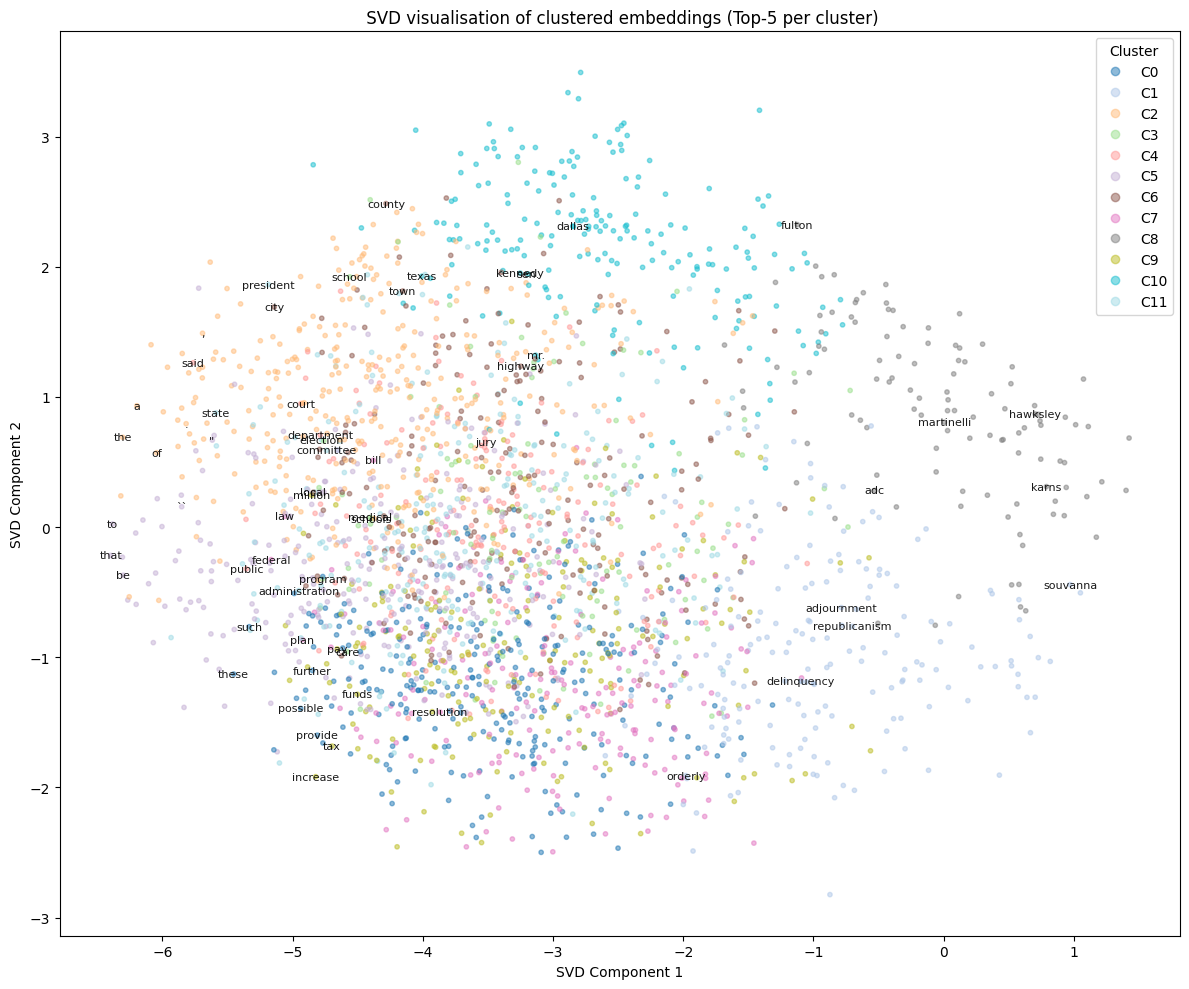

In [9]:
plot_clusters_svd(
    X=X,
    cluster_ids=tagger.labels_,
    vocab=vocab_words,
    input_tokens=input_tokens,
    topn_per_cluster=5,   
    figsize=(12, 10),
    random_state=42
)

### 1.6 Analysis (20%)
Based on the completed code, please conduct experiments to analyse different versions of GloVe (https://nlp.stanford.edu/projects/glove/). You can repeat the above procedures by using different GloVe models and compare their results.

#### Response

(Please note I have the code interleaving with the analysis so its easier to read.)

For my analysis, I aim to explore the success of K-means clustering in unsupervised PoS tagging. We first leverage the earlier suggested metrics to investigate how K-means clustering performed in this aspect. We then take a deeper look into the suitability of the metrics earlier derived in order to determine how well they capture the success or failure of K-means clustering. Moreover, we would investigate the success of K-means clustering in this task across the various models (the 50d, 100d, 6B-50d, 6B-200d GloVe embeddings). 

First, we collect some additional data. The following code being executed runs the earlier above defined functions for all the various datasets. 

 K-Means finished
Inertia: 1241.7422
Iterations: 81
Best init seed: 594336917
Data for: /home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/50d.txt
Mutual Information (I): 0.7191
Normalised Mutual Info (NMI): 0.2512
Homogeneity: 0.2451
Completeness: 0.2574
V-measure: 0.2511
Variation of Information: 4.2898


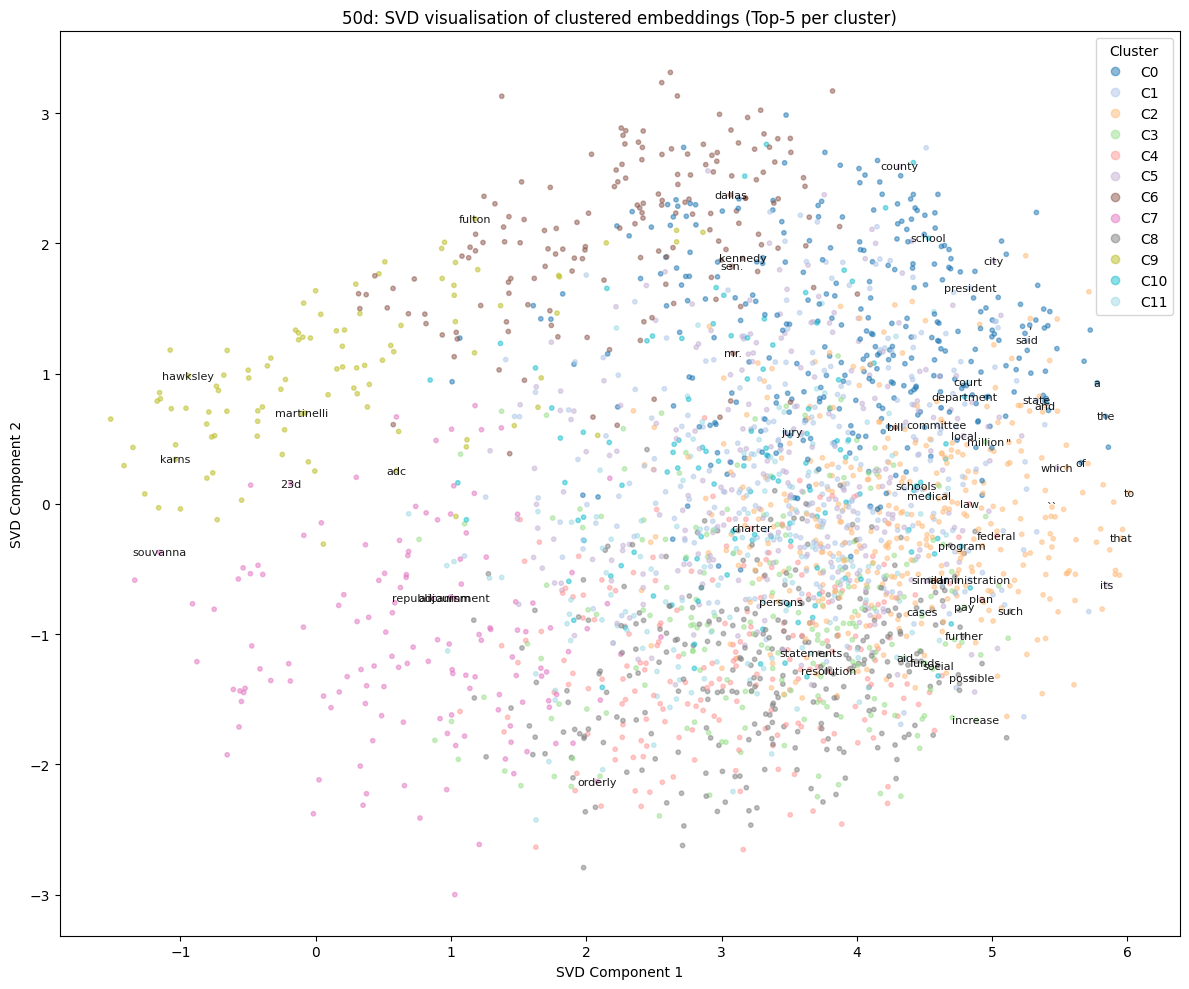

 K-Means finished
Inertia: 1468.8541
Iterations: 39
Best init seed: 184566854
Data for: /home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/100d.txt
Mutual Information (I): 0.6769
Normalised Mutual Info (NMI): 0.2378
Homogeneity: 0.2307
Completeness: 0.2452
V-measure: 0.2377
Variation of Information: 4.3407


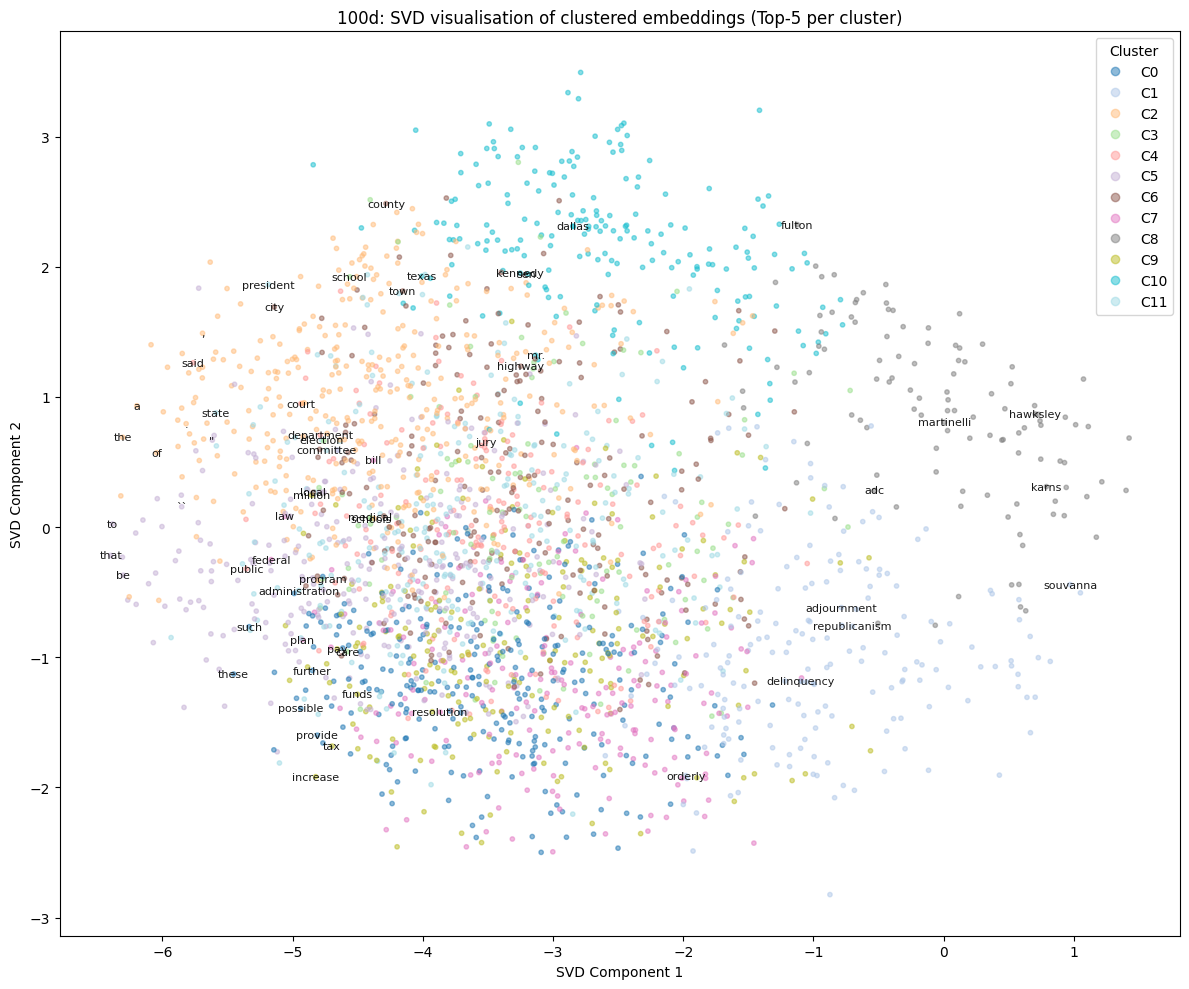

 K-Means finished
Inertia: 1445.8505
Iterations: 53
Best init seed: 1917963002
Data for: /home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/6B50d.txt
Mutual Information (I): 0.7669
Normalised Mutual Info (NMI): 0.2574
Homogeneity: 0.2613
Completeness: 0.2535
V-measure: 0.2573
Variation of Information: 4.4270


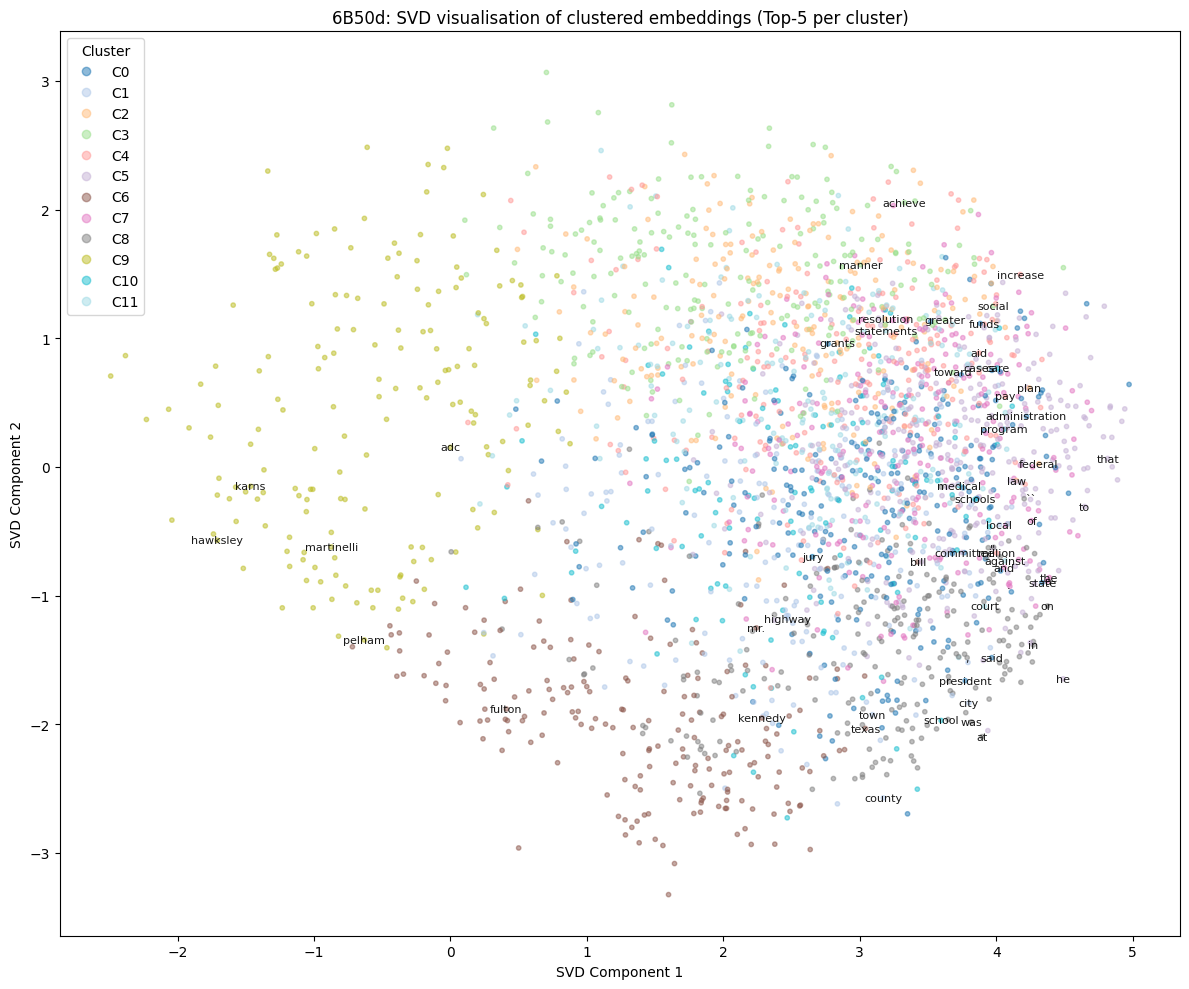

 K-Means finished
Inertia: 1847.4956
Iterations: 30
Best init seed: 1130604997
Data for: /home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/6B200d.txt
Mutual Information (I): 0.7048
Normalised Mutual Info (NMI): 0.2475
Homogeneity: 0.2401
Completeness: 0.2552
V-measure: 0.2474
Variation of Information: 4.2877


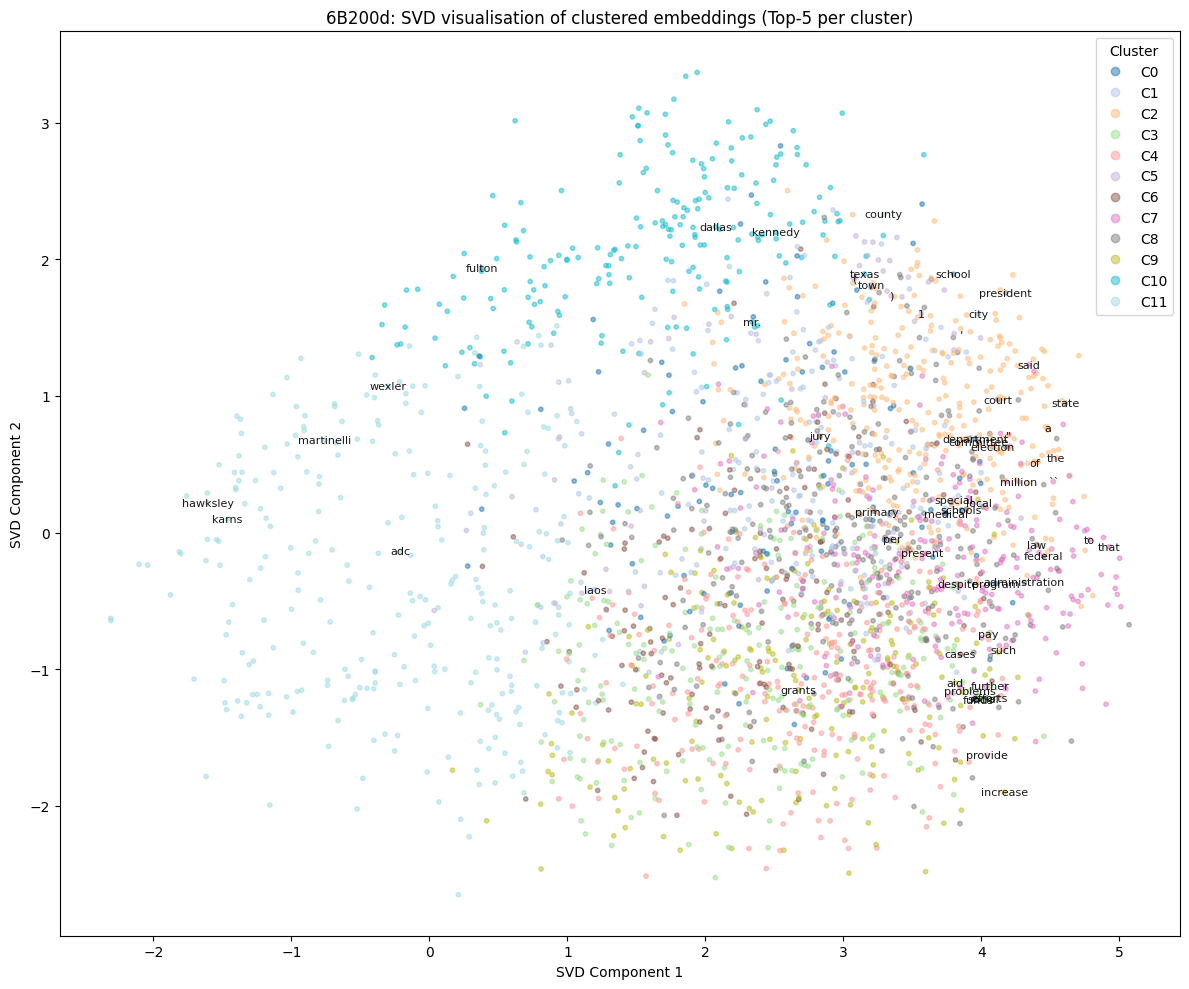

In [10]:
paths = [
    ("/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/50d.txt", 50, "50d"), 
    ("/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/100d.txt", 100, "100d"), 
    ("/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/6B50d.txt", 50, "6B50d"), 
    ("/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/6B200d.txt", 200, "6B200d"), 
]

results = {}  # everything the analysis cells below need, per embedding

for path, dim, title in paths:
    # `gv`, not `glove_vectors`: Section 2 uses `glove_vectors`, which must stay the 100d model loaded in Section 0
    gv = load_glove(path, dim=dim)

    token_embeddings, vocab_words, X, input_tokens, gold_tags, stats = build_token_embeddings_and_gold_tags(
        tagged_sents=tagged_sents,
        glove_vectors=gv,
        lowercase=True
    )
    # GloVe files are sorted by corpus frequency, so a word's position in the file is its frequency rank
    glove_rank = {w: r for r, w in enumerate(gv) if w in token_embeddings}

    # Run K-Means clustering
    k = len(unique_upos)  # number of clusters = number of UPOS tags
    tagger = KMeansPOSTagger(k=k, n_init=50, max_iter=200, random_state=42)
    tagger.fit(X, vocab_words)
    word2cluster = tagger.word2cluster_

    # Map each token in the corpus to its cluster ID from KMeans
    cluster_ids_for_tokens = [word2cluster[w] for w in input_tokens]

    # Evaluate the PoS tagging performance
    C, clusters, tags = build_contingency(cluster_ids_for_tokens, gold_tags)
    I_score = mutual_information(C)
    NMI_score = normalised_mutual_information(C)
    H_score = homogeneity(C)
    Cmp_score = completeness(C)
    V_score = v_measure(C)
    VI_score = variation_of_information(C)

    results[title] = dict(
        X=X, vocab=vocab_words, tagger=tagger, input_tokens=input_tokens,
        gold_tags=gold_tags, C=C, tags=tags, glove_rank=glove_rank,
    )

    print(f"Data for: {path}")
    print(f"Mutual Information (I): {I_score:.4f}")
    print(f"Normalised Mutual Info (NMI): {NMI_score:.4f}")
    print(f"Homogeneity: {H_score:.4f}")
    print(f"Completeness: {Cmp_score:.4f}")
    print(f"V-measure: {V_score:.4f}")
    print(f"Variation of Information: {VI_score:.4f}")

    plot_clusters_svd(
        X=X,
        cluster_ids=tagger.labels_,
        vocab=vocab_words,
        input_tokens=input_tokens,
        topn_per_cluster=5,   
        figsize=(12, 10),
        random_state=42,
        title=title,
    )

We first approach the question of whether K-means has been successful from a high level. From examining the plots of the the various clusters, we see similar trends across all the 4 models of the GloVe embedding. We observe some distinct clusters forming - in the GloVe 100d data, we see the clusters of C10, C8, C5 and C2 being fairly obvious. These clusters seem fairly clean, where we have limited overlap with the other clusters. This, taken at face value, suggest that for at least these words, we have clustered them successfully. However, we should note at this point that the plots merely plot the clusters found, not necessarily its success of being able to derive PoS information. Moveover, we note from the plots the overlap of the remaining clusters, which is somewhat undesirable. 

We can next take a look at the actual metrics we have derived from the contingency matrix that was computed. Completeness and Homogeneity capture some of the potential failure modes of the clustering outcome - the mixing of tags within a cluster, and the splitting of clusters within a tag. These values range between 0 and 1, and should give us some indication about the overlap between the tags and the clusters we "discovered". NMI would also tell a similar story - it would indicate the knowledge we gain about the tags once we know the cluster (and vice versa), and indirectly the uncertainty left. The code below computes the metrics collected if the clustering was done randomly, rather than via K-means clustering. Unsurprisingly, the p-values of the output from K-means clustering is statistically significant at a 5% signficance level, which gives us some hope that our clustering does something positive. 

However, this dosen't necessarily mean that our clustering algorithm has been a success. Rather, it seems like there is a long way to go, given our NMI has value 0.2378, which is far below the value of 1 we should be aiming for (albeit 1 is not a value we can reach since ambiguous words belong to more than 1 cluster). This is similar for Homogeneity and Completeness, which both, despite being better than random, have a relatively poor score. This also seems to be the case across the models, with 50d, 6B50d and 6B200d all posting relatively similar results. Unfortunately, the scores here give us limited insight into why exactly we are having less than ideal scores. However, looking at the clusters and the anotated words, it gives us some ideas of why this might be the case, which we would investigate next. 


In [11]:
metric_fns = {
    "MI": mutual_information,
    "NMI": normalised_mutual_information,
    "Homogeneity": homogeneity,
    "Completeness": completeness,
    "V-measure": v_measure,
    "VI": variation_of_information,
}

def random_split_baseline(vocab_words, input_tokens, gold_tags, tags, runs=1000, seed=None):
    rng = np.random.default_rng(seed)
    scores = {m: [] for m in metric_fns}
    for _ in range(runs):
        labels = rng.integers(0, tags, size=len(vocab_words))
        word2random = dict(zip(vocab_words, labels))
        C_rand, _, _ = build_contingency([word2random[w] for w in input_tokens], gold_tags)
        for m, fn in metric_fns.items():
            scores[m].append(fn(C_rand))
    return {m: (np.array(v), np.mean(v), np.std(v, ddof=1)) for m, v in scores.items()}

res = results['100d']
runs = 10000
base = random_split_baseline(res["vocab"], res["input_tokens"], res["gold_tags"], len(unique_upos), runs=runs)

for m, fn in metric_fns.items():
    score, (v, mean, sd) = fn(res["C"]), base[m]
    if m == "VI":
        n_as_good = (v <= score).sum()
    else:
        n_as_good = (v >= score).sum()
    p = (1 + n_as_good) / (1 + runs)
    print(f"{m}: K-means = {score:.4f}, random = {mean:.4f} ± {sd:.4f}, p = {p:.3f}")

MI: K-means = 0.6769, random = 0.5787 ± 0.0427, p = 0.017
NMI: K-means = 0.2378, random = 0.1807 ± 0.0131, p = 0.000
Homogeneity: K-means = 0.2307, random = 0.1972 ± 0.0146, p = 0.017
Completeness: K-means = 0.2452, random = 0.1655 ± 0.0119, p = 0.000
V-measure: K-means = 0.2377, random = 0.1800 ± 0.0131, p = 0.000
VI: K-means = 4.3407, random = 5.2732 ± 0.0809, p = 0.000


Here, we inspect each of the clusters and the words they contain. The following code works through the clusters to identify the majority tag, and a breakdown per tag of the words in the cluster. Subsequently, we also look at the tags and how they are split into the various clusters.

Here, it becomes clear from the results that the clusters do not represent the PoS tagging as we had hoped. Rather, the words are semantically grouped along topics, for instance, for the 100d model, C4 is clusters around the words related to court cases, C3 clusters around teaching, C7 groups words that are related to legislature, and C9 for finance. We further see that 10 out of 12 have their majority tag being a noun, and most clusters having a mix of tags within them. This further reinforces the view that the clusters do not actually reflect the PoS tagging we expected. This is probably because while the embeddings do probably encode some notion of syntactic meaning, many of its dimensions capture rich semantic meaning, and this is thus what the clusters are based off on. This seems to be the case not only for the 100 dimension embeddings, but also the 200 and 50 dimension embeddings. 

This seems to be the case across the various models. Taking the example of the 50d vs 100d models, we would expect that a directly comparison across them to be a comparison if the number of dimensions would impact the quality of clusters when K-means clustering is applied. However, we find that they share relatively similar V-measures and homogeneity. They both seems to encode the same topics in the clusters, and we could take this as an indication that the extra dimensions do not necessarily group words by part of speach, and that instead perhaps it was capturing more semantic meaning. 

Despite this, there is still some limited success in this aspect - specifically when we consider the DET, ., PRON, PRT, 90% of words belong in 2 selected clusters, although this is still heavily includes alot of other tagged words.

In [12]:
from collections import Counter, defaultdict

def l2_normalise(M: np.ndarray) -> np.ndarray: # helper for us to compute square distance to centroids
    return M / (np.linalg.norm(M, axis=1, keepdims=True))


def cluster_diagnostics(res: dict) -> dict:
    Xn = l2_normalise(res["X"])
    labels = res["tagger"].labels_
    cent = res["tagger"].centroids_
    d2 = (Xn ** 2).sum(1, keepdims=True) + (cent ** 2).sum(1) - 2 * Xn @ cent.T # we basically use the same functions as in the fitting process

    tag_counts = defaultdict(Counter) 
    for w, t in zip(res["input_tokens"], res["gold_tags"]):
        tag_counts[w][t] += 1

    C, tags = res["C"], res["tags"]
    return dict(
        Xn=Xn,
        labels=labels,
        d2=d2,
        tag_counts=tag_counts,
        majority={w: c.most_common(1)[0][0] for w, c in tag_counts.items()},
        cluster_tag={k: tags[int(C[k].argmax())] for k in range(C.shape[0])},  # many-to-one label of each cluster
        freq=Counter(res["input_tokens"]),
    )

def cluster_contents(name: str, res: dict, n_central: int = 8, n_per_tag: int = 6, max_tags: int = 4):
    d = cluster_diagnostics(res)
    labels, vocab, C = d["labels"], np.array(res["vocab"]), res["C"]

    print(f"{name}:")
    for c in sorted(range(C.shape[0]), key=lambda c: -(labels == c).sum()):
        members = np.where(labels == c)[0]
        central = vocab[members[np.argsort(d["d2"][members, c])[:n_central]]]
        by_tag = defaultdict(list)
        for i in members:
            by_tag[d["majority"][vocab[i]]].append(vocab[i])

        print(f"\nC{c}: {len(members)} words, {int(C[c].sum())} tokens, majority token tag {d['cluster_tag'][c]}")
        print(f"   closest to centroid: {', '.join(central)}")

        for t, ws in sorted(by_tag.items(), key=lambda kv: -len(kv[1]))[:max_tags]:
            top = sorted(ws, key=lambda w: -d["freq"][w])[:n_per_tag]
            print(f"   {t:5} ({len(ws):3d} words): {', '.join(top)}")

for model in["100d", "50d", "6B50d", "6B200d"]:
    cluster_contents(model, results[model])

100d:

C2: 366 words, 4905 tokens, majority token tag DET
   closest to centroid: ., came, first, only, last, one, time, before
   NOUN  (109 words): year, house, home, time, sunday, years
   VERB  ( 96 words): was, has, been, had, were, made
   NUM   ( 44 words): one, two, 1, 10, five, three
   ADJ   ( 43 words): new, last, other, first, present, special

C0: 292 words, 490 tokens, majority token tag NOUN
   closest to centroid: certain, result, change, especially, possible, particularly, important, similar
   NOUN  (125 words): primary, system, future, problems, problem, action
   ADJ   ( 82 words): such, further, possible, social, similar, greater
   VERB  ( 60 words): provide, limited, use, concerned, achieve, caused
   ADV   ( 22 words): generally, nevertheless, somewhat, fully, consistently, specifically

C5: 288 words, 2142 tokens, majority token tag VERB
   closest to centroid: even, come, so, what, but, because, not, how
   VERB  (111 words): be, would, is, will, have, are
   

In [13]:
def tag_cluster_spread(name: str, res: dict):
    """For each gold tag: which clusters its words land in, and what share of its words each cluster gets.
    A word counts towards the tag it has most often in Brown."""
    d = cluster_diagnostics(res)
    w2c = res["tagger"].word2cluster_
    print(f"{name}:")
    for t in res["tags"]:
        words = [w for w in d["tag_counts"] if d["majority"][w] == t]
        spread = Counter(w2c[w] for w in words)

        print(f"{t:5} ({len(words):4d} words, {len(spread):2d} clusters): " + ", ".join(f"C{c} {m} ({m / len(words):.0%})" for c, m in spread.most_common()))

for name in ["50d", "100d"]:
    tag_cluster_spread(name, results[name])


50d:
.     (  11 words,  2 clusters): C2 6 (55%), C0 5 (45%)
ADJ   ( 327 words, 12 clusters): C8 85 (26%), C2 39 (12%), C5 39 (12%), C0 35 (11%), C7 31 (9%), C1 29 (9%), C3 19 (6%), C4 17 (5%), C10 14 (4%), C11 14 (4%), C6 3 (1%), C9 2 (1%)
ADP   (  51 words,  8 clusters): C0 21 (41%), C2 15 (29%), C5 8 (16%), C8 3 (6%), C4 1 (2%), C1 1 (2%), C3 1 (2%), C7 1 (2%)
ADV   ( 117 words,  9 clusters): C2 57 (49%), C8 19 (16%), C0 12 (10%), C5 8 (7%), C1 7 (6%), C4 5 (4%), C7 4 (3%), C11 3 (3%), C3 2 (2%)
CONJ  (   6 words,  3 clusters): C2 4 (67%), C3 1 (17%), C6 1 (17%)
DET   (  22 words,  3 clusters): C2 16 (73%), C0 4 (18%), C5 2 (9%)
NOUN  (1318 words, 12 clusters): C1 167 (13%), C5 160 (12%), C6 154 (12%), C8 129 (10%), C0 107 (8%), C3 107 (8%), C9 94 (7%), C11 94 (7%), C4 94 (7%), C10 81 (6%), C2 74 (6%), C7 57 (4%)
NUM   (  86 words,  5 clusters): C0 56 (65%), C3 24 (28%), C9 4 (5%), C2 1 (1%), C5 1 (1%)
PRON  (  15 words,  1 clusters): C2 15 (100%)
PRT   (   9 words,  2 clusters): C2

To conclude, we recognise that our metrics and plots give us some notion of how well the clustering algorithm did in extracting PoS data, which it succeeded to a limited extent. It did better than if the clusters were assigned by random, but upon deeper inspection, it turns out our clusters do not represent PoS tags, but rather semantic topics, with each cluster containing a mix of tags. 

## 2. Apply Word2Vec to Unsupervised Extractive Summarisation

In this section, we use Word2Vec embeddings to perform unsupervised extractive summarisation.  
The core idea of extractive summarisation is to select the most representative and informative sentences from the original document to form a concise summary without rewriting.


In this task, we use TextRank to summarise CNNDM dataset.

### 2.1 Load Document-Summary Paris from CNNDM
We use the first 100 lines of data for experiments. Please download the test.csv file from the Moodle page. To ensure text quality and consistency, we perform text cleaning before using the data as model inputs.

In [14]:
import pandas as pd
from typing import Tuple

import re
import html

def clean_text(s: str) -> str:
    s = html.unescape(s)
    s = s.replace("\xa0", " ").replace("\u200b", "").replace("\ufeff", "")
    s = s.replace("\n", " ").replace("\r", " ").replace("\t", " ")
    s = s.replace("“", '"').replace("”", '"').replace("’", "'").replace("‘", "'")
    s = s.replace("–", "-").replace("—", "-").replace("…", "...")
    s = re.sub(r"http\S+|www\.\S+", "", s)
    s = re.sub(r"\s+", " ", s)
    s = s.strip().lower()
    return s


def extract_cnndm_test_first_n(
    csv_path: str,
    n: int = 100,
    article_col: str = "article",
    summary_col: str = "highlights",
) -> Tuple[list, list]:
    """
    Extract the first N samples from a CNNDM CSV file,
    clean & lowercase text, and return (inputs, references).
    """
    df = pd.read_csv(csv_path)
    assert article_col in df.columns and summary_col in df.columns, \
        f"Missing required columns: '{article_col}' or '{summary_col}'"

    n = min(n, len(df))
    sub = df.iloc[:n].copy()

    inputs = [clean_text(str(x)) for x in sub[article_col].fillna("")]
    references = [clean_text(str(x)) for x in sub[summary_col].fillna("")]

    return inputs, references

cnndm_path = "/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/cnndm_test.csv"
docs, summaries = extract_cnndm_test_first_n(cnndm_path, n=100)


### 2.2 Convert Documents into Sentence Embeddings

In this step, we split each document into sentences and convert them into embeddings:
- Use nltk sent_tokenize for sentence segmentation.
- Tokenise each sentence and look up GloVe embeddings.
- Compute the average of token vectors to get a sentence embedding (use zero vector if no tokens found).
- Record each sentence’s document index.

Outputs inclue:
- sentence_embeddings: matrix of all sentence vectors
- sentences: corresponding sentence texts
- doc_index: mapping of each sentence to its document.

In [15]:
import numpy as np
import nltk
from typing import List, Tuple

nltk.download('punkt')

def compute_sentence_embeddings(
    docs: List[str],
    glove_vectors: dict,
) -> Tuple[np.ndarray, List[str], List[int]]:
    """
    Segment documents into sentences and compute sentence embeddings
    by averaging pre-trained GloVe word embeddings.

    Parameters
    ----------
    docs : list[str]
        List of input article texts.
    glove_vectors : dict
        Pre-trained GloVe word embeddings {token: vector}.

    Returns
    -------
    sentence_embeddings : np.ndarray [num_sentences, dim]
        Sentence-level embedding matrix.
    sentences : list[str]
        List of sentences in the same order as embeddings.
    doc_index : list[int]
        Document index for each sentence (e.g., sentence i belongs to docs[doc_index[i]]).
    """
    all_sentences = []
    doc_index = []

    for doc_id, text in enumerate(docs):
        sents = nltk.sent_tokenize(text)
        all_sentences.extend(sents)
        doc_index.extend([doc_id] * len(sents))

    sentence_vecs = []
    for sent in all_sentences:
        tokens = sent.split()  
        vecs = [glove_vectors[w] for w in tokens if w in glove_vectors]
        if len(vecs) == 0:
            sentence_vecs.append(np.zeros(next(iter(glove_vectors.values())).shape))
        else:
            sentence_vecs.append(np.mean(vecs, axis=0))

    sentence_embeddings = np.vstack(sentence_vecs) # first index says the sentence, 2nd says the specific embedding dimension

    return sentence_embeddings, all_sentences, doc_index


sentence_embeddings, sentences, doc_index = compute_sentence_embeddings(docs, glove_vectors)
# sentence_embeddings.shape

[nltk_data] Downloading package punkt to /home/potato/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/potato/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


### 2.3 TextRank for Unsupervised Summarisation. (30%)

Please refer to this paper for the algorithm https://aclanthology.org/W04-3252.pdf.

You can directly call the PageRank algorithm through `nextworkx`: https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html

In [16]:
import numpy as np
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from typing import List

class TextRankSummarizer:
    """
    Minimal TextRank implementation for unsupervised extractive summarisation.
    Uses PageRank over a sentence similarity graph.
    """

    def __init__(self, topk: int = 3):
        """
        Parameters
        ----------
        topk : int
            Number of sentences to extract per document.
        """
        self.topk = topk

    # Please complete your code here.
    def summarise(self, s_emb: np.ndarray[np.ndarray], s: list[str], d_indices: list[int]) -> list[str]:
        """ 
        This function will generate self.topk number of sentences for each index. 
        """ 
        summaries = [] 

        # split the sentence embedding matrix into matrices for each document. 
        s_emb_split = []
        s_split = []
        curr_doc = 0
        doc_s_emb = [] 
        doc_s = []
        for i, d_index in enumerate(d_indices): 
            if d_index != curr_doc: 
                s_emb_split.append(doc_s_emb)
                s_split.append(doc_s)
                doc_s_emb = [] 
                doc_s = []
                curr_doc = d_index
            doc_s_emb.append(s_emb[i])     
            doc_s.append(s[i])
        s_emb_split.append(doc_s_emb)
        s_split.append(doc_s)

        for doc_emb, doc_sentences in zip(s_emb_split, s_split):
            similarity = cosine_similarity(doc_emb)
            np.fill_diagonal(similarity, 0)
            similarity = np.clip(similarity, 0, None)

            graph = nx.from_numpy_array(similarity)
            scores = nx.pagerank(graph) # we can change alpha
            top = sorted(scores, key=scores.get, reverse=True)[:self.topk]
            summaries.append(" ".join([doc_sentences[i] for i in sorted(top)]))
        return summaries

In [17]:
textrank = TextRankSummarizer(topk=3)

system_summaries = textrank.summarise(sentence_embeddings, sentences, doc_index)
print(system_summaries[0])


with increasing numbers of people taking to the skies, some experts are questioning if having such packed out planes is putting passengers at risk. this week, a u.s consumer advisory group set up by the department of transportation said at a public hearing that while the government is happy to set standards for animals flying on planes, it doesn't stipulate a minimum amount of space for humans. but these tests are conducted using planes with 31 inches between each row of seats, a standard which on some airlines has decreased, reported the detroit news.


### 2.4 Evaluation using Rouge

We evaluate the quality of the system-generated summaries (system_summaries) against the gold references (summaries) using ROUGE metrics.
ROUGE (Recall-Oriented Understudy for Gisting Evaluation) is a standard evaluation metric for summarisation, measuring the lexical overlap between system outputs and human-written summaries.

You can install the rouge package by:
```
!pip install rouge-score
```

In [18]:
from rouge_score import rouge_scorer

def evaluate_rouge(system_summaries, gold_summaries):
    """
    Compute average ROUGE-1/2/L F1 scores over the dataset.
    """
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
    scores = {'rouge1': 0, 'rouge2': 0, 'rougeL': 0}
    n = len(system_summaries)

    for sys_sum, gold_sum in zip(system_summaries, gold_summaries):
        s = scorer.score(gold_sum, sys_sum)
        for key in scores:
            scores[key] += s[key].fmeasure

    for key in scores:
        scores[key] /= n
    return scores

rouge_scores = evaluate_rouge(system_summaries, summaries)
print("ROUGE scores:", rouge_scores)


ROUGE scores: {'rouge1': 0.3021590882851186, 'rouge2': 0.09748888770642178, 'rougeL': 0.1834947092932144}


### 2.5 Discussion and Analysis (30%)

Please discuss the result compared with other extractive models, such as the Lead-N model (https://arxiv.org/pdf/1908.08345). You may need to perform additional experiments to demonstrate your analysis (please write and excute your code below).

#### Response

For this discussion and analysis, we look to interpret how well the textrank algorithm worked. We further wish to analyse if other extractive models might work better in this respect. We might, at a high level, describe a generated summary to be successful if it correctly specifies the contents of the document in a limited number of sentences, and does so in a coherent manner. 

Again, we need to understand the metrics that are being used, in this instance the ROUGE scores. As mentioned in the above linked paper, ROUGE-1 and ROUGE-2 are means of assessing informativeness with unigram and bigram overlap, while ROUGE-L measures the longest common subsequence. All 3 of these metrics use the F1 score of the various overlaps. This metric should be able to capture whether our generated summary contains some of the key words / phrases which contain the meaning of the document. 

However, we note that ROUGE would match exact words / pairs of words, which may unfairly penalise the summaries provided if they vary even slightly from the "golden" summaries. We should note that the rouge score dosen't take into account the readability or coherence of our summaries, which would affect the quality of our summary significantly. 

Below, we execute a few models, which include the Lead-N model, Random-N models. Something we realise here is that surprisingly, the simple model which is Lead-3 does well, recording the highest ROUGE scores, as compared to Random-3 and TextRank-3. 

In [19]:
import random

# Group sentences by document 
doc_sents = [[] for _ in docs]
for sent, d in zip(sentences, doc_index):
    doc_sents[d].append(sent)

def lead_n(doc_sents, n=3):
    return [" ".join(sents[:n]) for sents in doc_sents]

def random_n(doc_sents, n=3, seed=None):
    rng = random.Random(seed)
    out = []
    for sents in doc_sents:
        idx = sorted(rng.sample(range(len(sents)), min(n, len(sents))))
        out.append(" ".join(sents[i] for i in idx))
    return out

def sent_length(outputs, doc_sents, refs, n):
    gold_len = np.mean([len(r.split()) for r in refs])

    print(f"Reference: {gold_len:.0f} words per summary")
    for name, out in outputs.items():
        words = [len(s.split()) for s in out]
        print(f"{name}: {np.mean(words):.0f} words per summary")


textrank_3 = TextRankSummarizer(topk=3)

outputs = {
    "TextRank-3": textrank_3.summarise(sentence_embeddings, sentences, doc_index),
    "Lead-3": lead_n(doc_sents, 3),
    "Random-3": random_n(doc_sents, 3, seed=0),
}
results = {name : evaluate_rouge(output, summaries) for name, output in outputs.items()}

print(f"TextRank-3:\n Rouge1: {results['TextRank-3']['rouge1']}\n Rouge2: {results['TextRank-3']['rouge2']}\n RougeL: {results['TextRank-3']['rougeL']}")
print(f"Lead-3:\n Rouge1: {results['Lead-3']['rouge1']}\n Rouge2: {results['Lead-3']['rouge2']}\n RougeL: {results['Lead-3']['rougeL']}")
print(f"Random-3:\n Rouge1: {results['Random-3']['rouge1']}\n Rouge2: {results['Random-3']['rouge2']}\n RougeL: {results['Random-3']['rougeL']}")

sent_length(outputs, doc_sents, summaries, n=3)

TextRank-3:
 Rouge1: 0.3021590882851186
 Rouge2: 0.09748888770642178
 RougeL: 0.1834947092932144
Lead-3:
 Rouge1: 0.3943078875823744
 Rouge2: 0.17096181321430684
 RougeL: 0.2504193348203577
Random-3:
 Rouge1: 0.28168246473944264
 Rouge2: 0.07790515373521878
 RougeL: 0.17546746073779373
Reference: 52 words per summary
TextRank-3: 97 words per summary
Lead-3: 77 words per summary
Random-3: 65 words per summary



Investigating further into this, we recognise that this might be the case for just the CNNDM dataset. We need to recognise that the CNN/DailyMail dataset is a news article dataset. Due to the style of writing, we might expect the Lead-3 model to do well compared to the other models, as most news articles tend to place headlines / succinct summaries of the article at the very front of the document. 

In order to further assess the performance of the textrank algorithm, and other extractive models, we ought to also consider other datasets, which might yield different results due to the different style of writing. Hence, we further examine an alternative dataset - booksum, which we have obtained at this link: https://huggingface.co/datasets/kmfoda/booksum/blob/main/train.csv. This should ideally give us an alternative perspective on how our models perform. 


In [20]:
def extract_booksum_sample(csv_path, n=100, seed=0):
    """
    Sample n chapter-summary pairs from BookSum (one summary per chapter),
    cleaned the same way as CNNDM.
    """
    df = pd.read_csv(csv_path)
    df = df.drop_duplicates("chapter_path")   
    sub = df.sample(n=n, random_state=seed)  
    inputs = [clean_text(str(x)) for x in sub["chapter"]]
    references = [clean_text(str(x)) for x in sub["summary_text"]]
    return inputs, references

booksum_path = "/home/potato/Documents/Github/PartII/II-NLP/Assignment-2/data/booksum.csv"
book_docs, book_summaries = extract_booksum_sample(booksum_path, n=100)
book_emb, book_sents, book_doc_index = compute_sentence_embeddings(book_docs, glove_vectors)

In [21]:
book_doc_sents = [[] for _ in book_docs]
for sent, d in zip(book_sents, book_doc_index):
    book_doc_sents[d].append(sent)

textrank_3 = TextRankSummarizer(topk=3)

book_outputs = {
    "TextRank-3": textrank_3.summarise(book_emb, book_sents, book_doc_index),
    "Lead-3": lead_n(book_doc_sents, 3),
    "Random-3": random_n(book_doc_sents, 3, seed=0),
}
book_results = {name: evaluate_rouge(output, book_summaries) for name, output in book_outputs.items()}

print(f"TextRank-3:\n Rouge1: {book_results['TextRank-3']['rouge1']}\n Rouge2: {book_results['TextRank-3']['rouge2']}\n RougeL: {book_results['TextRank-3']['rougeL']}")
print(f"Lead-3:\n Rouge1: {book_results['Lead-3']['rouge1']}\n Rouge2: {book_results['Lead-3']['rouge2']}\n RougeL: {book_results['Lead-3']['rougeL']}")
print(f"Random-3:\n Rouge1: {book_results['Random-3']['rouge1']}\n Rouge2: {book_results['Random-3']['rouge2']}\n RougeL: {book_results['Random-3']['rougeL']}")

sent_length(book_outputs, book_doc_sents, book_summaries, n=3)

TextRank-3:
 Rouge1: 0.2372852293174329
 Rouge2: 0.03144244362308337
 RougeL: 0.11706554037617557
Lead-3:
 Rouge1: 0.15863904665370826
 Rouge2: 0.025949502178765328
 RougeL: 0.08972885285248942
Random-3:
 Rouge1: 0.12140775301309746
 Rouge2: 0.01474233178834276
 RougeL: 0.07421627287055116
Reference: 393 words per summary
TextRank-3: 144 words per summary
Lead-3: 72 words per summary
Random-3: 53 words per summary


Looking at the booksum dataset, we obtain a different result - we see that the scores of the textrank algorithm is higher than both the lead and random, which suggests that with other documents, the textrank algorithm outperforms the naive algorithms in providing a summary. We could interpret this higher score over the lead-n as partly due to the difference in writing style, but we might attribute the higher score over the randomly chosen sentences to be the textrank algorithm being able to correctly identify sentences whose embedding is the closest to the average of all other embeddings in the document. 

Something else we should note is that the length of the generated summaries can impact the scores report. Since ROUGE combines precision and recall to compute F1, increasing additional words will not lower recall, but may reduce precision. This is however influenced by the length of the generated summary with respect to the reference summary. If we are to look at BookSum, the reference summaries have an average of 393 words, which is far longer than the 3 sentence summaries being generated. When comparing this across the summaries generated with textrank, lead-n and random-n, we note that TextRank produced summaries with the highest word count (144 vs 72 vs 53), and also the highest score, potentially because the scores are limited by recall. This is in line with our expectation that when summaries are shorter than the reference, the ROUGE score favours longer summaries. Going back to the suggestion from the previous paragraph, we might note that the higher score on BookSum for TextRank-3 may be a symptom of a longer summary length rather than its ability to select better sentences.

When we take a look at the CNNDM, we see the other side of this effect. With CNNDM-10 below, the number of words in the summary is higher than in the reference, leading to poorer precision, and overall lower scores. Perhaps what we should do alternatively would be to utilise similar algorithms to generate summaries of the same word count, rather than the same number of sentences, as this should eliminate this factor and give a fairer comparison to gauge which algorithm selects the best content. 

In [22]:
textrank_10 = TextRankSummarizer(topk=10)

book_outputs_10 = {
    "TextRank-10": textrank_10.summarise(book_emb, book_sents, book_doc_index),
    "Lead-10": lead_n(book_doc_sents, 10),
    "Random-10": random_n(book_doc_sents, 10, seed=0),
}
book_results_10 = {name: evaluate_rouge(out, book_summaries) for name, out in book_outputs_10.items()}

print(f"BookSum-10:")
print(f"TextRank-10:\n Rouge1: {book_results_10['TextRank-10']['rouge1']}\n Rouge2: {book_results_10['TextRank-10']['rouge2']}\n RougeL: {book_results_10['TextRank-10']['rougeL']}")
print(f"Lead-10:\n Rouge1: {book_results_10['Lead-10']['rouge1']}\n Rouge2: {book_results_10['Lead-10']['rouge2']}\n RougeL: {book_results_10['Lead-10']['rougeL']}")
print(f"Random-10:\n Rouge1: {book_results_10['Random-10']['rouge1']}\n Rouge2: {book_results_10['Random-10']['rouge2']}\n RougeL: {book_results_10['Random-10']['rougeL']}")

sent_length(book_outputs_10, book_doc_sents, book_summaries, n=10)

textrank_10 = TextRankSummarizer(topk=10)

outputs = {
    "TextRank-10": textrank_10.summarise(sentence_embeddings, sentences, doc_index),
    "Lead-10": lead_n(doc_sents, 10),
    "Random-10": random_n(doc_sents, 10, seed=0),
}
results = {name : evaluate_rouge(output, summaries) for name, output in outputs.items()}

print(f"\nCNNDM-10:")
print(f"TextRank-10:\n Rouge1: {results['TextRank-10']['rouge1']}\n Rouge2: {results['TextRank-10']['rouge2']}\n RougeL: {results['TextRank-10']['rougeL']}")
print(f"Lead-10:\n Rouge1: {results['Lead-10']['rouge1']}\n Rouge2: {results['Lead-10']['rouge2']}\n RougeL: {results['Lead-10']['rougeL']}")
print(f"Random-10:\n Rouge1: {results['Random-10']['rouge1']}\n Rouge2: {results['Random-10']['rouge2']}\n RougeL: {results['Random-10']['rougeL']}")

sent_length(outputs, doc_sents, summaries, n=10)

BookSum-10:
TextRank-10:
 Rouge1: 0.3290894677269005
 Rouge2: 0.05177192456577039
 RougeL: 0.14059744241803857
Lead-10:
 Rouge1: 0.27795925692138096
 Rouge2: 0.04459640350216564
 RougeL: 0.13061282391813114
Random-10:
 Rouge1: 0.26172092510573036
 Rouge2: 0.03442382140891091
 RougeL: 0.1232926303247483
Reference: 393 words per summary
TextRank-10: 423 words per summary
Lead-10: 239 words per summary
Random-10: 199 words per summary

CNNDM-10:
TextRank-10:
 Rouge1: 0.21826164060772804
 Rouge2: 0.09302607574906725
 RougeL: 0.14158912934602
Lead-10:
 Rouge1: 0.2708652296036961
 Rouge2: 0.13520867053262478
 RougeL: 0.1842522406599523
Random-10:
 Rouge1: 0.25376702315859645
 Rouge2: 0.10365102211069306
 RougeL: 0.1576251824050314
Reference: 52 words per summary
TextRank-10: 280 words per summary
Lead-10: 230 words per summary
Random-10: 213 words per summary
